# 14.11.26 Мимик 

Посмотрела журнал all_events_mimic3.csv, в нём около 16,7 млн строк, 22 типа событий и 38 915 госпитализаций. За один случай взяла одну госпитализацию (HADM_ID), а на train и test разделила по пациентам (SUBJECT_ID), чтобы госпитализации одного пациента не попали в обе части

У 26 004 госпитализаций в журнале не было отметок поступления и окончания. Для всех нашла обе даты в ADMISSIONS.csv. Там, где отметки уже были в журнале, даты полностью совпали. После исключения случаев, где окончание стояло раньше поступления или совпадало с ним, осталось 38 868 госпитализаций

DFG. Для первого графа оставила переводы, вход и выход из реанимации и смену службы. У 99,93% госпитализаций с восстановленными датами в журнале нет ни одного из этих событий. На графе такие маршруты выглядят как admission -> discharge, хотя у пациентов могли быть другие записи. Поэтому для первого эксперимента с перемещениями взяла группу, где обе границы уже были в журнале: 10 208 госпитализаций в train и 2 675 в test.

Сети Петри. По train построила две сети через Inductive Miner. В первой оставила события отдельно, во второй объединила записи с одинаковым временем в один шаг. Например, transfer_in и transfer_out с одной отметкой времени стали одним событием, тк по журналу нельзя определить их порядок. На test у обеих сетей fitness округлился до 1,0000, а precision 0,4411 и 0,4505 соответственно

По частотам переходов и интервалам из train сгенерировала 2 675 траекторий и сравнила их с реальными test. Медиана времени до окончания госпитализации получилась 6,84 дня в синтетических данных и 6,73 дня в реальных. Медиана длины маршрута в обоих случаях - 5 шагов. Пока генератор работает по DFG, а сети Петри проверены отдельно

In [ ]:
from pathlib import Path

import pandas


file_path = Path(
    r"D:\Универ\4 курс\Диплом\all_events_mimic3.csv"
)

column_separator = ","

header_table = pandas.read_csv(
    file_path,
    sep=column_separator,
    encoding="utf-8-sig",
    nrows=0
)

column_names = header_table.columns.tolist()

if len(column_names) < 2:
    raise ValueError(
        f"Прочитался только один столбец: {column_names}. "
        "Проверь разделитель CSV. Возможно, нужен ';'."
    )

print("Столбцы в файле:")
for column_name in column_names:
    print(column_name)


number_of_rows = 0
empty_values_by_column = dict.fromkeys(column_names, 0)

file_parts = pandas.read_csv(
    file_path,
    sep=column_separator,
    encoding="utf-8-sig",
    dtype=str,
    keep_default_na=False,
    chunksize=100_000
)

for file_part in file_parts:
    number_of_rows += len(file_part)

    for column_name in column_names:
        column_values = file_part[column_name].str.strip()
        empty_values = column_values == ""
        empty_values_by_column[column_name] += int(empty_values.sum())


print("\nВсего строк:", number_of_rows)

print("\nПустые значения по столбцам:")
for column_name, number_of_empty_values in empty_values_by_column.items():
    print(f"{column_name}: {number_of_empty_values}")

Столбцы в файле:
Unnamed: 0
SUBJECT_ID
HADM_ID
ICUSTAY_ID
EVENT_TIME
EVENT_TYPE
DETAILS


In [ ]:
from collections import Counter
from random import Random


event_counts_with_admission = Counter()
event_counts_without_admission = Counter()
patient_admission_pairs = set()

columns_to_read = [
    "SUBJECT_ID",
    "HADM_ID",
    "EVENT_TYPE"
]

file_parts = pandas.read_csv(
    file_path,
    sep=column_separator,
    encoding="utf-8-sig",
    usecols=columns_to_read,
    dtype=str,
    keep_default_na=False,
    chunksize=100_000
)

for file_part in file_parts:
    for column_name in columns_to_read:
        file_part[column_name] = file_part[column_name].str.strip()

    has_admission = file_part["HADM_ID"] != ""

    rows_with_admission = file_part.loc[has_admission]
    rows_without_admission = file_part.loc[~has_admission]

    counts_with_admission = rows_with_admission["EVENT_TYPE"].value_counts()
    counts_without_admission = rows_without_admission["EVENT_TYPE"].value_counts()

    event_counts_with_admission.update(counts_with_admission.to_dict())
    event_counts_without_admission.update(counts_without_admission.to_dict())

    unique_pairs = rows_with_admission[
        ["SUBJECT_ID", "HADM_ID"]
    ].drop_duplicates()

    patient_admission_pairs.update(
        unique_pairs.itertuples(index=False, name=None)
    )


# Таблица типов событий
event_types = sorted(
    set(event_counts_with_admission) | set(event_counts_without_admission)
)

event_summary_rows = []

for event_type in event_types:
    event_summary_rows.append({
        "Событие": event_type,
        "Строк с госпитализацией": event_counts_with_admission[event_type],
        "Строк без госпитализации": event_counts_without_admission[event_type]
    })

event_summary_table = pandas.DataFrame(event_summary_rows)

event_summary_table = event_summary_table.sort_values(
    "Строк с госпитализацией",
    ascending=False
)

print("Типов событий:", len(event_summary_table))
print(event_summary_table.head(30).to_string(index=False))

event_summary_file_path = file_path.parent / "mimic3_event_types.csv"
event_summary_table.to_csv(
    event_summary_file_path,
    sep=";",
    encoding="utf-8-sig",
    index=False
)

admissions_table = pandas.DataFrame(
    sorted(patient_admission_pairs),
    columns=["SUBJECT_ID", "HADM_ID"]
)

if admissions_table["HADM_ID"].duplicated().any():
    raise ValueError(
        "Один HADM_ID связан с несколькими пациентами. "
        "Нужно проверить идентификаторы до разделения."
    )

admission_counts_by_patient = admissions_table.groupby("SUBJECT_ID").size()

print("\nПациентов с госпитализациями:", len(admission_counts_by_patient))
print("Госпитализаций:", len(admissions_table))
print(
    "Пациентов с несколькими госпитализациями:",
    int((admission_counts_by_patient > 1).sum())
)


# Train и test
patient_identifiers = sorted(admissions_table["SUBJECT_ID"].unique())

if len(patient_identifiers) < 2:
    raise ValueError("Для разделения нужны хотя бы два пациента.")

random_generator = Random(42)
random_generator.shuffle(patient_identifiers)

number_of_test_patients = round(len(patient_identifiers) * 0.20)
number_of_test_patients = max(
    1, min(number_of_test_patients, len(patient_identifiers) - 1)
)

test_patient_identifiers = set(
    patient_identifiers[:number_of_test_patients]
)

admissions_table["split"] = "train"

belongs_to_test = admissions_table["SUBJECT_ID"].isin(
    test_patient_identifiers
)

admissions_table.loc[belongs_to_test, "split"] = "test"

split_summary = admissions_table.groupby("split").agg(
    patients=("SUBJECT_ID", "nunique"),
    admissions=("HADM_ID", "nunique")
)

print("\nРазделение:")
print(split_summary.to_string())

split_file_path = file_path.parent / "mimic3_admissions_split.csv"
admissions_table.to_csv(
    split_file_path,
    sep=";",
    encoding="utf-8-sig",
    index=False
)

print("\nТипы событий:", event_summary_file_path)
print("Список госпитализаций train/test:", split_file_path)

Типов событий: 22
           Событие  Строк с госпитализацией  Строк без госпитализации
        lab_result                  5019772                   1592854
         input_end                  2076226                         0
       input_start                  2076226                         0
    datetime_event                  1637048                       797
            output                  1150626                      1632
prescription_start                  1024914                         0
  prescription_end                  1024319                         0
              note                   385889                     30918
      microbiology                   164620                         0
   procedure_start                   148511                         0
     procedure_end                   148511                         0
       transfer_in                    57329                         0
      transfer_out                    44426                         0
  

In [ ]:

boundary_event_types = ["admission", "discharge", "death"]

columns_to_read = ["HADM_ID", "EVENT_TIME", "EVENT_TYPE"]

file_parts = pandas.read_csv(
    file_path,
    sep=column_separator,
    encoding="utf-8-sig",
    usecols=columns_to_read,
    dtype=str,
    keep_default_na=False,
    chunksize=100_000
)

boundary_event_parts = []

for file_part in file_parts:
    file_part["HADM_ID"] = file_part["HADM_ID"].str.strip()
    file_part["EVENT_TYPE"] = file_part["EVENT_TYPE"].str.strip()

    has_admission_identifier = file_part["HADM_ID"] != ""
    is_boundary_event = file_part["EVENT_TYPE"].isin(boundary_event_types)

    selected_rows = has_admission_identifier & is_boundary_event
    boundary_events = file_part.loc[selected_rows].copy()

    if not boundary_events.empty:
        boundary_event_parts.append(boundary_events)

boundary_events_table = pandas.concat(
    boundary_event_parts,
    ignore_index=True
)

boundary_events_table["EVENT_TIME"] = pandas.to_datetime(
    boundary_events_table["EVENT_TIME"].str.strip(),
    format="mixed",
    errors="raise"
)


admission_boundaries_table = admissions_table.copy()

for event_type in boundary_event_types:
    selected_rows = boundary_events_table["EVENT_TYPE"] == event_type
    events_of_one_type = boundary_events_table.loc[selected_rows]

    event_summary = events_of_one_type.groupby("HADM_ID").agg(
        event_count=("EVENT_TIME", "size"),
        first_event_time=("EVENT_TIME", "min")
    )

    event_summary = event_summary.rename(columns={
        "event_count": event_type + "_count",
        "first_event_time": event_type + "_time"
    })

    admission_boundaries_table = admission_boundaries_table.merge(
        event_summary,
        left_on="HADM_ID",
        right_index=True,
        how="left",
        validate="one_to_one"
    )

    count_column = event_type + "_count"

    admission_boundaries_table[count_column] = (
        admission_boundaries_table[count_column].fillna(0).astype(int)
    )

    admission_boundaries_table["has_" + event_type] = (
        admission_boundaries_table[count_column] > 0
    )


print("Сочетания отметок по госпитализациям:")

boundary_combinations = admission_boundaries_table.groupby([
    "split",
    "has_admission",
    "has_discharge",
    "has_death"
]).size().unstack("split", fill_value=0)

print(boundary_combinations.to_string())

print("\nГоспитализаций с повторными отметками:")
for event_type in boundary_event_types:
    count_column = event_type + "_count"
    repeated_event = admission_boundaries_table[count_column] > 1
    print(event_type, ":", int(repeated_event.sum()))


# Порядок поступления и выписки
admission_time = admission_boundaries_table["admission_time"]
discharge_time = admission_boundaries_table["discharge_time"]
death_time = admission_boundaries_table["death_time"]

print("\nГоспитализаций с обеими отметками:",
      int((admission_time.notna() & discharge_time.notna()).sum()))
print("Выписка раньше поступления:",
      int((discharge_time < admission_time).sum()))
print("Выписка одновременно с поступлением:",
      int((discharge_time == admission_time).sum()))


# Смерть относительно выписки
print("\nСмерть раньше выписки:",
      int((death_time < discharge_time).sum()))
print("Смерть одновременно с выпиской:",
      int((death_time == discharge_time).sum()))
print("Смерть позже выписки:",
      int((death_time > discharge_time).sum()))
print("Есть отметка смерти, но нет отметки выписки:",
      int((death_time.notna() & discharge_time.isna()).sum()))
print("Смерть раньше поступления:",
      int((death_time < admission_time).sum()))

Сочетания отметок по госпитализациям:
split                                  test  train
has_admission has_discharge has_death             
False         False         False      5166  20838
True          True          False      2423   9201
                            True        259   1028

Госпитализаций с повторными отметками:
admission : 0
discharge : 0
death : 0

Госпитализаций с обеими отметками: 12911
Выписка раньше поступления: 28
Выписка одновременно с поступлением: 0

Смерть раньше выписки: 5
Смерть одновременно с выпиской: 1275
Смерть позже выписки: 7
Есть отметка смерти, но нет отметки выписки: 0
Смерть раньше поступления: 25


In [ ]:
# Проверяем, не записан ли один HADM_ID двумя способами
identifier_check_table = admission_boundaries_table[
    ["HADM_ID", "SUBJECT_ID", "has_admission", "has_discharge"]
].copy()

identifier_check_table["normalized_hospitalization_id"] = (
    identifier_check_table["HADM_ID"]
    .str.replace(r"^([0-9]+)\.0+$", r"\1", regex=True)
)

identifier_check_table["normalized_patient_id"] = (
    identifier_check_table["SUBJECT_ID"]
    .str.replace(r"^([0-9]+)\.0+$", r"\1", regex=True)
)

identifier_check_table["has_both_marks"] = (
    identifier_check_table["has_admission"]
    & identifier_check_table["has_discharge"]
)

identifier_check_table["identifier_changed"] = (
    identifier_check_table["HADM_ID"]
    != identifier_check_table["normalized_hospitalization_id"]
)

print("Формат HADM_ID по наличию отметок:")
print(pandas.crosstab(
    identifier_check_table["has_both_marks"],
    identifier_check_table["identifier_changed"]
).to_string())

normalized_cases = identifier_check_table.groupby(
    "normalized_hospitalization_id"
).agg(
    original_identifiers=("HADM_ID", "nunique"),
    patients=("normalized_patient_id", "nunique"),
    any_case_with_marks=("has_both_marks", "any"),
    all_cases_with_marks=("has_both_marks", "all")
)

merged_cases = normalized_cases["original_identifiers"] > 1

merged_cases_with_different_marks = (
    merged_cases
    & (normalized_cases["patients"] == 1)
    & normalized_cases["any_case_with_marks"]
    & ~normalized_cases["all_cases_with_marks"]
)

print("\nГоспитализаций, у которых нашлись два написания ID:",
      int(merged_cases.sum()))

print("Из них у одного написания есть обе отметки, у другого нет:",
      int(merged_cases_with_different_marks.sum()))

print("Совпадений ID, связанных с разными пациентами:",
      int((normalized_cases["patients"] > 1).sum()))

Формат HADM_ID по наличию отметок:
identifier_changed   True
has_both_marks           
False               26004
True                12911

Госпитализаций, у которых нашлись два написания ID: 0
Из них у одного написания есть обе отметки, у другого нет: 0
Совпадений ID, связанных с разными пациентами: 0


In [ ]:

source_file_path = Path(
    r"D:\Универ\4 курс\Диплом\mimic-iii-clinical-database-1.4\mimic-iii-clinical-database-1.4\ADMISSIONS.csv"
)

source_admissions = pandas.read_csv(
    source_file_path,
    dtype=str,
    keep_default_na=False
)

# Одинаковый формат столбцов и идентификаторов
source_admissions.columns = source_admissions.columns.str.strip().str.upper()

identifier_columns = ["SUBJECT_ID", "HADM_ID"]

source_admissions = source_admissions[
    identifier_columns + ["ADMITTIME", "DISCHTIME"]
].copy()

journal_admissions = admission_boundaries_table.copy()

for table in [source_admissions, journal_admissions]:
    for column_name in identifier_columns:
        table[column_name] = (
            table[column_name]
            .str.strip()
            .str.replace(r"^([0-9]+)\.0+$", r"\1", regex=True)
        )

# Сверка по пациенту и госпитализации
comparison_table = journal_admissions.merge(
    source_admissions,
    on=identifier_columns,
    how="left",
    validate="one_to_one",
    indicator=True
)

for column_name in ["ADMITTIME", "DISCHTIME"]:
    comparison_table[column_name] = pandas.to_datetime(
        comparison_table[column_name].str.strip().replace("", pandas.NA),
        format="mixed",
        errors="raise"
    )

# Госпитализации без отметок в журнале
without_marks = (
    ~comparison_table["has_admission"]
    & ~comparison_table["has_discharge"]
)

found_in_source = comparison_table["_merge"] == "both"

has_both_source_dates = (
    comparison_table["ADMITTIME"].notna()
    & comparison_table["DISCHTIME"].notna()
)

source_dates_in_order = (
    comparison_table["ADMITTIME"] < comparison_table["DISCHTIME"]
)

print("Без обеих отметок в журнале:", int(without_marks.sum()))
print("Из них найдены в ADMISSIONS:",
      int((without_marks & found_in_source).sum()))
print("Из них имеют обе даты в ADMISSIONS:",
      int((without_marks & has_both_source_dates).sum()))
print("Из них поступление строго раньше выписки:",
      int((without_marks & source_dates_in_order).sum()))

can_compare_dates = (
    comparison_table["has_admission"]
    & comparison_table["has_discharge"]
    & has_both_source_dates
)

both_dates_match = (
    (comparison_table["admission_time"] == comparison_table["ADMITTIME"])
    & (comparison_table["discharge_time"] == comparison_table["DISCHTIME"])
)

print("\nСлучаев, где можно сверить обе даты:", int(can_compare_dates.sum()))
print("Из них обе даты совпали:",
      int((can_compare_dates & both_dates_match).sum()))
print("Из них хотя бы одна дата отличается:",
      int((can_compare_dates & ~both_dates_match).sum()))

Без обеих отметок в журнале: 26004
Из них найдены в ADMISSIONS: 26004
Из них имеют обе даты в ADMISSIONS: 26004
Из них поступление строго раньше выписки: 25985

Случаев, где можно сверить обе даты: 12911
Из них обе даты совпали: 12911
Из них хотя бы одна дата отличается: 0


In [ ]:
from collections import Counter


# Госпитализации с правильным порядком дат
valid_admissions = comparison_table.loc[
    comparison_table["ADMITTIME"] < comparison_table["DISCHTIME"],
    ["SUBJECT_ID", "HADM_ID", "ADMITTIME", "DISCHTIME", "split"]
].copy()

print("Госпитализаций с правильным порядком дат:")
print(valid_admissions["split"].value_counts().to_string())


events_inside_by_type = Counter()
admissions_with_events_inside = set()

number_before_admission = 0
number_after_discharge = 0

file_parts = pandas.read_csv(
    file_path,
    sep=column_separator,
    encoding="utf-8-sig",
    usecols=["SUBJECT_ID", "HADM_ID", "EVENT_TIME", "EVENT_TYPE"],
    dtype=str,
    keep_default_na=False,
    chunksize=100_000
)

for file_part in file_parts:
    for column_name in ["SUBJECT_ID", "HADM_ID"]:
        file_part[column_name] = (
            file_part[column_name]
            .str.strip()
            .str.replace(r"^([0-9]+)\.0+$", r"\1", regex=True)
        )

    file_part["EVENT_TYPE"] = file_part["EVENT_TYPE"].str.strip()

    # Границы из ADMISSIONS, смерть смотрим отдельно
    boundary_event_types = ["admission", "discharge", "death"]
    is_other_event = ~file_part["EVENT_TYPE"].isin(boundary_event_types)
    other_events = file_part.loc[is_other_event]

    events_with_boundaries = other_events.merge(
        valid_admissions,
        on=["SUBJECT_ID", "HADM_ID"],
        how="inner",
        validate="many_to_one"
    )

    event_times = pandas.to_datetime(
        events_with_boundaries["EVENT_TIME"].str.strip(),
        format="mixed",
        errors="raise"
    )

    before_admission = event_times < events_with_boundaries["ADMITTIME"]
    after_discharge = event_times > events_with_boundaries["DISCHTIME"]
    inside_admission = ~before_admission & ~after_discharge

    number_before_admission += int(before_admission.sum())
    number_after_discharge += int(after_discharge.sum())

    events_inside = events_with_boundaries.loc[inside_admission]

    event_type_counts = events_inside["EVENT_TYPE"].value_counts()
    events_inside_by_type.update(event_type_counts.to_dict())
    admissions_with_events_inside.update(events_inside["HADM_ID"].unique())


print("\nСобытий до поступления:", number_before_admission)
print("Событий после окончания госпитализации:", number_after_discharge)
print("Событий в пределах госпитализации:", sum(events_inside_by_type.values()))

has_internal_events = valid_admissions["HADM_ID"].isin(
    admissions_with_events_inside
)

print("\nГоспитализации с событиями между границами или на их отметках:")
print(pandas.crosstab(
    valid_admissions["split"],
    has_internal_events
).rename(columns={False: "Нет событий", True: "Есть события"}).to_string())

print("\nТипы событий внутри госпитализации:")
for event_type, number_of_events in events_inside_by_type.most_common():
    print(f"{event_type}: {number_of_events}")

Госпитализаций с правильным порядком дат:
split
train    31032
test      7836

Событий до поступления: 626283
Событий после окончания госпитализации: 77280
Событий в пределах госпитализации: 14364734

Госпитализации с событиями между границами или на их отметках:
HADM_ID  Нет событий  Есть события
split                             
test              16          7820
train             39         30993

Типы событий внутри госпитализации:
lab_result: 4639970
input_start: 2070878
input_end: 2065082
datetime_event: 1632408
output: 1148559
prescription_end: 974450
prescription_start: 828265
note: 375347
microbiology: 149494
procedure_start: 147917
procedure_end: 143223
transfer_in: 45950
cpt_procedure: 38432
transfer_out: 34331
callout_created: 16223
callout_outcome: 15758
service_change: 14474
icu_in: 13314
icu_out: 10659


In [ ]:
import json
import shutil
import subprocess

import pandas


movement_event_types = [
    "transfer_in",
    "transfer_out",
    "icu_in",
    "icu_out",
    "service_change"
]

identifier_columns = ["SUBJECT_ID", "HADM_ID"]
columns_to_read = identifier_columns + ["EVENT_TIME", "EVENT_TYPE"]

file_parts = pandas.read_csv(
    file_path,
    sep=column_separator,
    encoding="utf-8-sig",
    usecols=columns_to_read,
    dtype=str,
    keep_default_na=False,
    chunksize=100_000
)

movement_event_parts = []
number_of_rows_read = 0

for file_part in file_parts:
    file_part["source_order"] = range(
        number_of_rows_read,
        number_of_rows_read + len(file_part)
    )

    number_of_rows_read += len(file_part)
    file_part["EVENT_TYPE"] = file_part["EVENT_TYPE"].str.strip()

    is_movement = file_part["EVENT_TYPE"].isin(movement_event_types)
    movement_events = file_part.loc[is_movement].copy()

    for column_name in identifier_columns:
        movement_events[column_name] = (
            movement_events[column_name]
            .str.strip()
            .str.replace(r"^([0-9]+)\.0+$", r"\1", regex=True)
        )

    movement_events = movement_events.merge(
        valid_admissions,
        on=identifier_columns,
        how="inner",
        validate="many_to_one"
    )

    movement_events["EVENT_TIME"] = pandas.to_datetime(
        movement_events["EVENT_TIME"].str.strip(),
        format="mixed",
        errors="raise"
    )

    inside_hospitalization = (
        (movement_events["EVENT_TIME"] >= movement_events["ADMITTIME"])
        & (movement_events["EVENT_TIME"] <= movement_events["DISCHTIME"])
    )

    movement_events = movement_events.loc[inside_hospitalization].copy()

    movement_events["event_order"] = 1
    movement_event_parts.append(movement_events)


# Границы из ADMISSIONS
start_events = valid_admissions.copy()
start_events["EVENT_TYPE"] = "admission"
start_events["EVENT_TIME"] = start_events["ADMITTIME"]
start_events["event_order"] = 0
start_events["source_order"] = 0

end_events = valid_admissions.copy()
end_events["EVENT_TYPE"] = "discharge"
end_events["EVENT_TIME"] = end_events["DISCHTIME"]
end_events["event_order"] = 2
end_events["source_order"] = 0

event_log = pandas.concat(
    [start_events, *movement_event_parts, end_events],
    ignore_index=True
)

event_log = event_log.sort_values(
    ["HADM_ID", "EVENT_TIME", "event_order", "source_order"]
)

print("Внутренних событий:", int((event_log["event_order"] == 1).sum()))


# Train и test
train_log = event_log.loc[event_log["split"] == "train"].copy()
test_log = event_log.loc[event_log["split"] == "test"].copy()

shared_patients = set(train_log["SUBJECT_ID"]) & set(test_log["SUBJECT_ID"])

if shared_patients:
    raise ValueError("Один и тот же пациент оказался в train и test.")

for split_name, split_log in [("train", train_log), ("test", test_log)]:
    number_of_events_by_case = split_log.groupby("HADM_ID").size()

    print(f"\n{split_name}:")
    print("Госпитализаций:", len(number_of_events_by_case))
    print("Всего событий с началом и концом:", len(split_log))
    print(
        "Маршрутов только admission → discharge:",
        int((number_of_events_by_case == 2).sum())
    )


# Соседние события внутри одной госпитализации
def make_transition_table(log_table):
    transitions = log_table[
        ["HADM_ID", "EVENT_TYPE", "EVENT_TIME"]
    ].copy()

    cases = transitions.groupby("HADM_ID", sort=False)

    transitions["to_activity"] = cases["EVENT_TYPE"].shift(-1)
    transitions["next_time"] = cases["EVENT_TIME"].shift(-1)

    transitions = transitions.loc[
        transitions["to_activity"].notna()
    ].copy()

    transitions = transitions.rename(
        columns={"EVENT_TYPE": "from_activity"}
    )

    time_difference = transitions["next_time"] - transitions["EVENT_TIME"]

    transitions["duration_hours"] = (
        time_difference.dt.total_seconds() / 3600
    )
    transitions["zero_interval"] = transitions["duration_hours"] == 0

    return transitions


train_transitions = make_transition_table(train_log)
test_transitions = make_transition_table(test_log)


# DFG только по train
transition_columns = ["from_activity", "to_activity"]

dfg_table = (
    train_transitions.groupby(transition_columns)
    .agg(
        transition_count=("duration_hours", "size"),
        zero_interval_count=("zero_interval", "sum"),
        median_hours=("duration_hours", "median")
    )
    .reset_index()
    .sort_values("transition_count", ascending=False)
)

total_outgoing = dfg_table.groupby("from_activity")[
    "transition_count"
].transform("sum")

dfg_table["transition_probability"] = (
    dfg_table["transition_count"] / total_outgoing
)

print("\nРазных связей в train:", len(dfg_table))
print("Переходов с нулевым временем в train:",
      int(train_transitions["zero_interval"].sum()))
print(dfg_table.head(20).round(3).to_string(index=False))


# Проверка test по готовому DFG
known_train_edges = dfg_table[transition_columns].copy()
known_train_edges["seen_in_train"] = True

test_check = test_transitions.merge(
    known_train_edges,
    on=transition_columns,
    how="left",
    validate="many_to_one"
)

unknown_test_transitions = test_check.loc[
    test_check["seen_in_train"].isna()
]

unknown_test_cases = unknown_test_transitions["HADM_ID"].nunique()
number_of_test_cases = test_log["HADM_ID"].nunique()

unknown_edges_table = (
    unknown_test_transitions.groupby(transition_columns)
    .size()
    .reset_index(name="transition_count_in_test")
    .sort_values("transition_count_in_test", ascending=False)
)

print("\nПроверка на test:")
print("Всего переходов:", len(test_transitions))
print("Переходов, которых не было в train:", len(unknown_test_transitions))
print("Разных новых связей:", len(unknown_edges_table))
print("Госпитализаций хотя бы с одной новой связью:", unknown_test_cases)
print(
    "Доля госпитализаций, где все связи известны, %:",
    round(100 * (number_of_test_cases - unknown_test_cases)
          / number_of_test_cases, 2)
)

if not unknown_edges_table.empty:
    print("\nНовые связи в test:")
    print(unknown_edges_table.to_string(index=False))


output_directory = file_path.parent

dfg_file_path = output_directory / "mimic3_movement_dfg_train.csv"
dfg_table.to_csv(dfg_file_path, sep=";", encoding="utf-8-sig", index=False)

test_file_path = output_directory / "mimic3_movement_unknown_test_edges.csv"
unknown_edges_table.to_csv(
    test_file_path,
    sep=";",
    encoding="utf-8-sig",
    index=False
)

print("\nТаблица DFG:", dfg_file_path)
print("Новые связи в test:", test_file_path)


# Рисунок DFG
graph_lines = ["digraph MIMIC_III {", "  rankdir=LR;"]

for row in dfg_table.itertuples(index=False):
    from_node = json.dumps(row.from_activity)
    to_node = json.dumps(row.to_activity)

    graph_lines.append(
        f'  {from_node} -> {to_node} [label="{row.transition_count}"];'
    )

graph_lines.append("}")

dot_file_path = output_directory / "mimic3_movement_dfg_train.dot"
dot_file_path.write_text("\n".join(graph_lines), encoding="utf-8")

graphviz_program = shutil.which("dot")

if graphviz_program is None:
    graphviz_path = r"C:\Program Files\Graphviz\bin\dot.exe"

    from pathlib import Path

    if Path(graphviz_path).is_file():
        graphviz_program = graphviz_path

if graphviz_program is not None:
    image_file_path = output_directory / "mimic3_movement_dfg_train.svg"

    subprocess.run(
        [graphviz_program, "-Tsvg", str(dot_file_path), "-o", str(image_file_path)],
        check=True
    )

    print("Рисунок DFG:", image_file_path)
else:
    print("Graphviz не найден. Файл графа сохранён:", dot_file_path)

Внутренних событий: 118728

train:
Госпитализаций: 31032
Всего событий с началом и концом: 155970
Маршрутов только admission → discharge: 20834

test:
Госпитализаций: 7836
Всего событий с началом и концом: 40494
Маршрутов только admission → discharge: 5163

Разных связей в train: 25
Переходов с нулевым временем в train: 57733
 from_activity    to_activity  transition_count  zero_interval_count  median_hours  transition_probability
   transfer_in   transfer_out             27115                27115         0.000                   0.746
     admission      discharge             20834                    0       169.750                   0.671
        icu_in    transfer_in             10511                10511         0.000                   0.999
   transfer_in service_change              9196                 9196         0.000                   0.253
  transfer_out    transfer_in              9193                    0        23.821                   0.339
  transfer_out      discharge 

In [ ]:
# Проверка прямых маршрутов
movement_counts = (
    event_log.loc[event_log["event_order"] == 1]
    .groupby("HADM_ID")
    .size()
)

hospitalization_check = comparison_table.loc[
    comparison_table["ADMITTIME"] < comparison_table["DISCHTIME"],
    ["HADM_ID", "split", "has_admission", "has_discharge"]
].copy()

hospitalization_check["boundary_source"] = "Границы восстановлены"

had_both_boundaries = (
    hospitalization_check["has_admission"]
    & hospitalization_check["has_discharge"]
)

hospitalization_check.loc[
    had_both_boundaries, "boundary_source"
] = "Границы уже были в CSV"

hospitalization_check["direct_route"] = (
    hospitalization_check["HADM_ID"].map(movement_counts).isna()
)

direct_route_summary = (
    hospitalization_check.groupby(["split", "boundary_source"])
    .agg(
        hospitalizations=("HADM_ID", "size"),
        direct_routes=("direct_route", "sum")
    )
)

direct_route_summary["direct_percent"] = (
    100
    * direct_route_summary["direct_routes"]
    / direct_route_summary["hospitalizations"]
)

print("Прямые маршруты по источнику границ:")
print(direct_route_summary.round(2).to_string())


# События с одинаковым временем
internal_events = event_log.loc[event_log["event_order"] == 1].copy()
boundary_events = event_log.loc[event_log["event_order"] != 1].copy()


def combine_event_names(event_names):
    sorted_event_names = sorted(event_names)
    return " + ".join(sorted_event_names)


grouped_internal_events = (
    internal_events.groupby(
        ["SUBJECT_ID", "HADM_ID", "split", "EVENT_TIME"],
        as_index=False,
        sort=False
    )
    .agg(
        EVENT_TYPE=("EVENT_TYPE", combine_event_names),
        original_event_count=("EVENT_TYPE", "size")
    )
)

grouped_internal_events["event_order"] = 1

grouped_event_log = pandas.concat(
    [boundary_events, grouped_internal_events],
    ignore_index=True
)

grouped_event_log = grouped_event_log.sort_values(
    ["HADM_ID", "EVENT_TIME", "event_order"]
)

simultaneous_groups = grouped_internal_events.loc[
    grouped_internal_events["original_event_count"] > 1
]

print("\nЧастые группы в train:")
train_groups = simultaneous_groups.loc[
    simultaneous_groups["split"] == "train", "EVENT_TYPE"
]
print(train_groups.value_counts().head(15).to_string())


# Train и test
grouped_train_log = grouped_event_log.loc[
    grouped_event_log["split"] == "train"
].copy()

grouped_test_log = grouped_event_log.loc[
    grouped_event_log["split"] == "test"
].copy()

grouped_train_transitions = make_transition_table(grouped_train_log)
grouped_test_transitions = make_transition_table(grouped_test_log)


# DFG по train
transition_columns = ["from_activity", "to_activity"]

grouped_dfg_table = (
    grouped_train_transitions.groupby(transition_columns)
    .agg(
        transition_count=("duration_hours", "size"),
        zero_interval_count=("zero_interval", "sum"),
        median_hours=("duration_hours", "median")
    )
    .reset_index()
    .sort_values("transition_count", ascending=False)
)

outgoing_counts = grouped_dfg_table.groupby("from_activity")[
    "transition_count"
].transform("sum")

grouped_dfg_table["transition_probability"] = (
    grouped_dfg_table["transition_count"] / outgoing_counts
)

print("\nDFG после объединения одновременных событий:")
print(grouped_dfg_table.head(20).round(3).to_string(index=False))


# Проверка test
grouped_test_check = grouped_test_transitions.merge(
    grouped_dfg_table[transition_columns],
    on=transition_columns,
    how="left",
    validate="many_to_one",
    indicator=True
)

unknown_grouped_transitions = grouped_test_check.loc[
    grouped_test_check["_merge"] == "left_only"
]

unknown_grouped_cases = unknown_grouped_transitions["HADM_ID"].nunique()
number_of_test_cases = grouped_test_log["HADM_ID"].nunique()

print("\nСравнение двух DFG:")
print("Связей в train до объединения:", len(dfg_table))
print("Связей в train после объединения:", len(grouped_dfg_table))
print("Нулевых интервалов в train до объединения:",
      int(train_transitions["zero_interval"].sum()))
print("Нулевых интервалов в train после объединения:",
      int(grouped_train_transitions["zero_interval"].sum()))
print("Неизвестных переходов в test после объединения:",
      len(unknown_grouped_transitions))
print("Госпитализаций test с неизвестной связью:",
      unknown_grouped_cases, "из", number_of_test_cases)

unknown_grouped_edges = (
    unknown_grouped_transitions.groupby(transition_columns)
    .size()
    .reset_index(name="count_in_test")
    .sort_values("count_in_test", ascending=False)
)

if not unknown_grouped_edges.empty:
    print("\nСамые частые неизвестные связи в test:")
    print(unknown_grouped_edges.head(15).to_string(index=False))

grouped_dfg_file_path = file_path.parent / "mimic3_simultaneous_dfg_train.csv"

grouped_dfg_table.to_csv(
    grouped_dfg_file_path,
    sep=";",
    encoding="utf-8-sig",
    index=False
)

print("\nТаблица сохранена:", grouped_dfg_file_path)

Прямые маршруты по источнику границ:
                              hospitalizations  direct_routes  direct_percent
split boundary_source                                                        
test  Границы восстановлены               5161           5159           99.96
      Границы уже были в CSV              2675              4            0.15
train Границы восстановлены              20824          20809           99.93
      Границы уже были в CSV             10208             25            0.24

Частые группы в train:
EVENT_TYPE
transfer_in + transfer_out                               13414
icu_out + transfer_in + transfer_out                      8160
icu_in + service_change + transfer_in                     5613
icu_in + transfer_in + transfer_out                       4526
service_change + transfer_in                              3582
icu_in + service_change + transfer_in + transfer_out       366
service_change + transfer_in + transfer_out                360
icu_out + service_c

In [ ]:
import pandas
import pm4py

from pm4py.objects.log.obj import Event, EventLog, Trace


# Госпитализации для сравнения
selected_hospitalizations = comparison_table.loc[
    comparison_table["has_admission"]
    & comparison_table["has_discharge"]
    & (comparison_table["ADMITTIME"] < comparison_table["DISCHTIME"]),
    "HADM_ID"
]

selected_identifiers = set(selected_hospitalizations)


# Журнал для PM4Py
def make_pm4py_log(log_table):
    process_log = EventLog()

    hospitalizations = log_table.groupby("HADM_ID", sort=False)

    for hospitalization_id, hospitalization_events in hospitalizations:
        trace = Trace(attributes={"concept:name": str(hospitalization_id)})

        for event_row in hospitalization_events.itertuples(index=False):
            event = Event({
                "concept:name": event_row.EVENT_TYPE,
                "time:timestamp": event_row.EVENT_TIME.to_pydatetime()
            })

            trace.append(event)

        process_log.append(trace)

    return process_log


# Два варианта журнала
log_versions = [
    ("События отдельно", event_log, "separate"),
    ("Одновременные события вместе", grouped_event_log, "grouped")
]

results = []

for version_name, version_log, file_suffix in log_versions:

    # Train и test
    selected_log = version_log.loc[
        version_log["HADM_ID"].isin(selected_identifiers)
    ]

    training_table = selected_log.loc[selected_log["split"] == "train"]
    testing_table = selected_log.loc[selected_log["split"] == "test"]

    training_log = make_pm4py_log(training_table)
    testing_log = make_pm4py_log(testing_table)

    print("\nВариант:", version_name)
    print("Госпитализаций в train:", len(training_log))
    print("Госпитализаций в test:", len(testing_log))

    # Восстановление сети по train
    petri_net, initial_marking, final_marking = (
        pm4py.discover_petri_net_inductive(
            training_log,
            noise_threshold=0.0
        )
    )

    # Проверка готовой сети на test
    fitness_result = pm4py.fitness_token_based_replay(
        testing_log,
        petri_net,
        initial_marking,
        final_marking
    )

    precision = pm4py.precision_token_based_replay(
        testing_log,
        petri_net,
        initial_marking,
        final_marking
    )

    generalization = pm4py.generalization_tbr(
        testing_log,
        petri_net,
        initial_marking,
        final_marking
    )

    simplicity = pm4py.simplicity_petri_net(
        petri_net,
        initial_marking,
        final_marking
    )

    results.append({
        "Вариант": version_name,
        "Fitness": fitness_result["log_fitness"],
        "Precision": precision,
        "Generalization (TBR на test)": generalization,
        "Simplicity": simplicity,
        "Места": len(petri_net.places),
        "Переходы сети": len(petri_net.transitions)
    })

    # Сохранение сети
    network_file_path = file_path.parent / f"mimic3_train_{file_suffix}.pnml"

    pm4py.write_pnml(
        petri_net,
        initial_marking,
        final_marking,
        str(network_file_path)
    )

    print("Сеть сохранена:", network_file_path)


# Таблица результатов
results_table = pandas.DataFrame(results)
print("\nСравнение сетей Петри:")
print(results_table.round(4).to_string(index=False))



  Welcome to PM4Py — Community Version
  Open-Source License (AGPL v3)

  📚 Docs & Examples:
     https://processintelligence.solutions/pm4py

  ⚖️  License: AGPL v3 — Commercial use requires open-sourcing your application.
     Business use without open-sourcing? A commercial license is available:
     https://processintelligence.solutions/pm4py#licensing





Вариант: События отдельно
Госпитализаций в train: 10208
Госпитализаций в test: 2675


c:\Users\wonewom\AppData\Local\Programs\Python\Python311\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
replaying log with TBR, completed traces :: 100%|██████████| 466/466 [00:00<00:00, 540.74it/s]


Сеть сохранена: D:\Универ\4 курс\Диплом\mimic3_train_separate.pnml

Вариант: Одновременные события вместе
Госпитализаций в train: 10208
Госпитализаций в test: 2675


replaying log with TBR, completed traces :: 100%|██████████| 496/496 [00:00<00:00, 814.45it/s] 

Сеть сохранена: D:\Универ\4 курс\Диплом\mimic3_train_grouped.pnml

Сравнение сетей Петри:
                     Вариант  Fitness  Precision  Generalization (TBR на test)  Simplicity  Места  Переходы сети
            События отдельно      1.0     0.4411                        0.9354      0.6629     26             33
Одновременные события вместе      1.0     0.4505                        0.7472      0.5701     21             40


In [ ]:
from random import Random

import pandas


# Train и test
selected_log = grouped_event_log.loc[
    grouped_event_log["HADM_ID"].isin(selected_identifiers)
].copy()

training_table = selected_log.loc[
    selected_log["split"] == "train"
].copy()

testing_table = selected_log.loc[
    selected_log["split"] == "test"
].copy()

print("Госпитализаций в train:", training_table["HADM_ID"].nunique())
print("Госпитализаций в test:", testing_table["HADM_ID"].nunique())


# Переходы и время из train
training_transitions = make_transition_table(training_table)

next_activities_by_activity = {}
transition_counts_by_activity = {}
observed_durations_by_transition = {}

for activity_pair, transition_rows in training_transitions.groupby(
    ["from_activity", "to_activity"]
):
    current_activity, next_activity = activity_pair

    if current_activity not in next_activities_by_activity:
        next_activities_by_activity[current_activity] = []
        transition_counts_by_activity[current_activity] = []

    next_activities_by_activity[current_activity].append(next_activity)

    transition_counts_by_activity[current_activity].append(
        len(transition_rows)
    )

    observed_durations_by_transition[activity_pair] = (
        transition_rows["duration_hours"].tolist()
    )


# Проверка прямого перехода
admission_transition_counts = transition_counts_by_activity["admission"]

direct_transition_count = len(
    observed_durations_by_transition.get(("admission", "discharge"), [])
)

direct_transition_probability = (
    direct_transition_count / sum(admission_transition_counts)
)

print(
    "Вероятность admission → discharge по train, %:",
    round(100 * direct_transition_probability, 3)
)


# Построение симуляции
random_generator = Random(42)
maximum_transitions = 2000


def simulate_hospitalization(case_identifier):
    current_activity = "admission"
    elapsed_hours = 0.0

    trajectory = [{
        "object_id": case_identifier,
        "state": current_activity,
        "time": elapsed_hours,
        "outcome": ""
    }]

    for transition_number in range(maximum_transitions):
        next_activity = random_generator.choices(
            next_activities_by_activity[current_activity],
            weights=transition_counts_by_activity[current_activity],
            k=1
        )[0]

        activity_pair = (current_activity, next_activity)

        duration_hours = random_generator.choice(
            observed_durations_by_transition[activity_pair]
        )

        elapsed_hours += duration_hours
        current_activity = next_activity

        outcome = ""
        if current_activity == "discharge":
            outcome = "hospitalization_ended"

        trajectory.append({
            "object_id": case_identifier,
            "state": current_activity,
            "time": elapsed_hours,
            "outcome": outcome
        })

        if current_activity == "discharge":
            return trajectory

    raise RuntimeError(
        f"Случай {case_identifier} не дошёл до discharge "
        f"за {maximum_transitions} переходов."
    )


# Синтетический журнал
number_of_synthetic_cases = testing_table["HADM_ID"].nunique()
synthetic_rows = []

for case_number in range(1, number_of_synthetic_cases + 1):
    case_identifier = f"synthetic_{case_number}"
    trajectory = simulate_hospitalization(case_identifier)
    synthetic_rows.extend(trajectory)

synthetic_log = pandas.DataFrame(synthetic_rows)

first_case_identifier = synthetic_log["object_id"].iloc[0]

print("\nПример синтетического маршрута:")
print(
    synthetic_log.loc[
        synthetic_log["object_id"] == first_case_identifier
    ].round({"time": 3}).to_string(index=False)
)


# Таблица реальных госпитализаций test
real_cases = testing_table.groupby("HADM_ID").agg(
    start_time=("EVENT_TIME", "min"),
    end_time=("EVENT_TIME", "max"),
    number_of_events=("EVENT_TYPE", "size")
)

real_cases["duration_days"] = (
    (real_cases["end_time"] - real_cases["start_time"])
    .dt.total_seconds() / 86400
)


# Таблица синтетических госпитализаций
synthetic_cases = synthetic_log.groupby("object_id").agg(
    duration_hours=("time", "max"),
    number_of_events=("state", "size")
)

synthetic_cases["duration_days"] = synthetic_cases["duration_hours"] / 24


# Сравнение с test
def summarize_cases(cases):
    return {
        "Госпитализаций": len(cases),
        "Среднее время до окончания, дни": cases["duration_days"].mean(),
        "Медиана времени до окончания, дни": cases["duration_days"].median(),
        "90-й процентиль времени, дни": cases["duration_days"].quantile(0.90),
        "Среднее число событий": cases["number_of_events"].mean(),
        "Медиана числа событий": cases["number_of_events"].median(),
        "Прямых маршрутов, %": 100 * (cases["number_of_events"] == 2).mean()
    }


comparison_results = pandas.DataFrame({
    "Реальные test": summarize_cases(real_cases),
    "Синтетические по train": summarize_cases(synthetic_cases)
})

print("\nСравнение реальных и синтетических маршрутов:")
print(comparison_results.round(3).to_string())


# Сохранение журнала
synthetic_file_path = file_path.parent / "mimic3_synthetic_grouped_dfg.csv"

synthetic_log.to_csv(
    synthetic_file_path,
    sep=";",
    encoding="utf-8-sig",
    index=False
)

print("\nСинтетический журнал:", synthetic_file_path)

Госпитализаций в train: 10208
Госпитализаций в test: 2675
Вероятность admission → discharge по train, %: 0.245

Пример синтетического маршрута:
  object_id                        state  time               outcome
synthetic_1                    admission 0.000                      
synthetic_1 service_change + transfer_in 0.024                      
synthetic_1   transfer_in + transfer_out 7.730                      
synthetic_1                    discharge 7.730 hospitalization_ended

Сравнение реальных и синтетических маршрутов:
                                   Реальные test  Синтетические по train
Госпитализаций                          2675.000                2675.000
Среднее время до окончания, дни           11.134                  10.725
Медиана времени до окончания, дни          6.730                   6.837
90-й процентиль времени, дни              24.128                  24.435
Среднее число событий                      5.714                   5.693
Медиана числа событий     

События отдельно
Рисунок сохранён: D:\Универ\4 курс\Диплом\mimic3_train_separate.svg


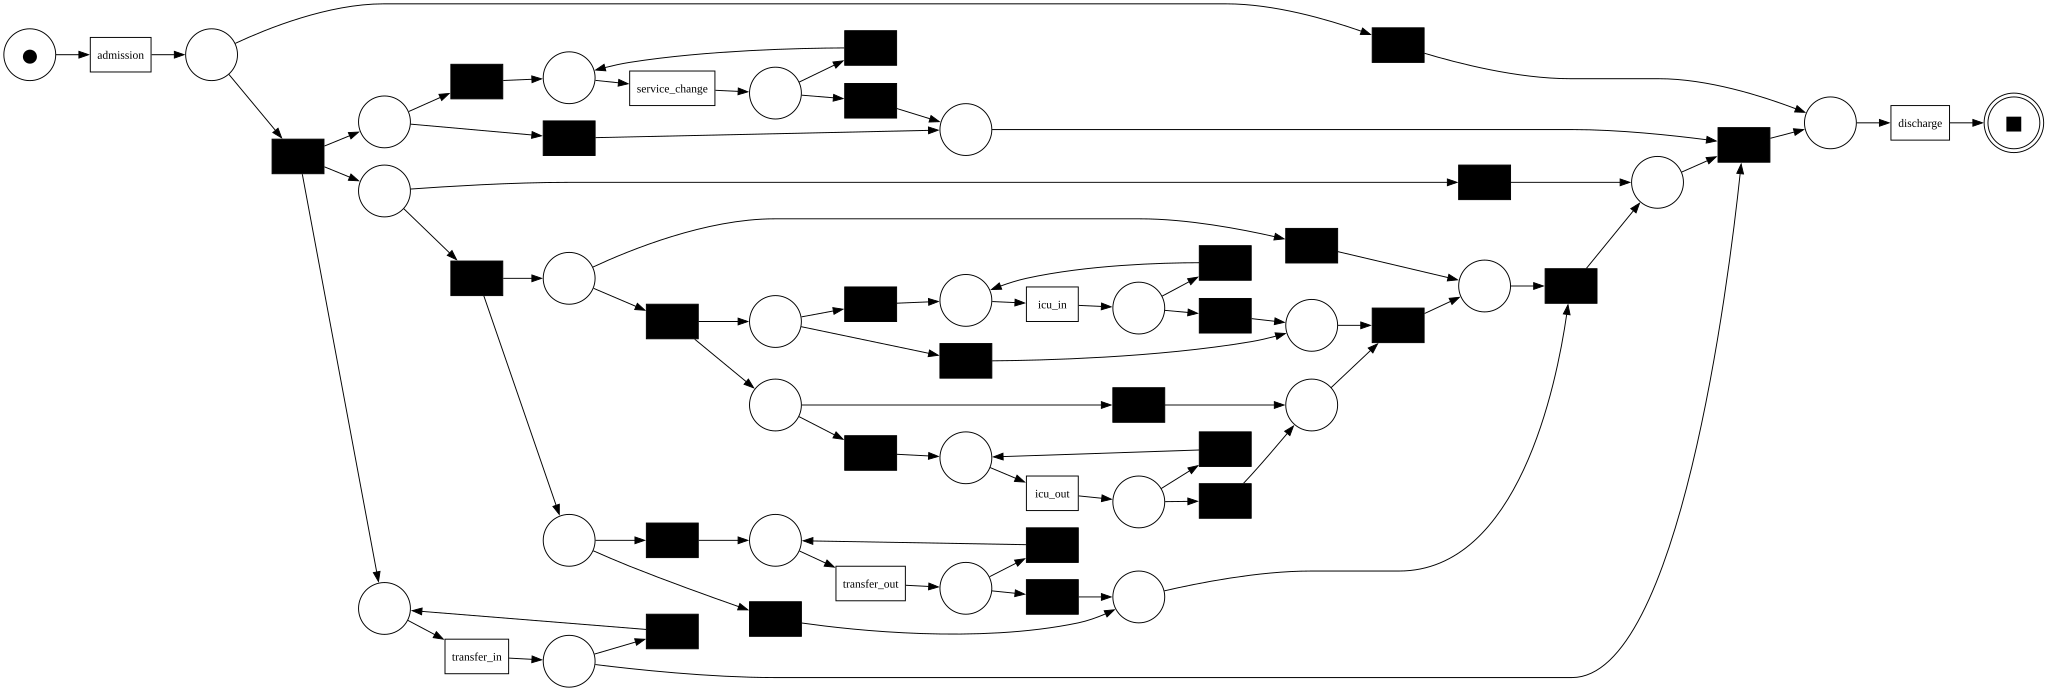

Одновременные события вместе
Рисунок сохранён: D:\Универ\4 курс\Диплом\mimic3_train_grouped.svg


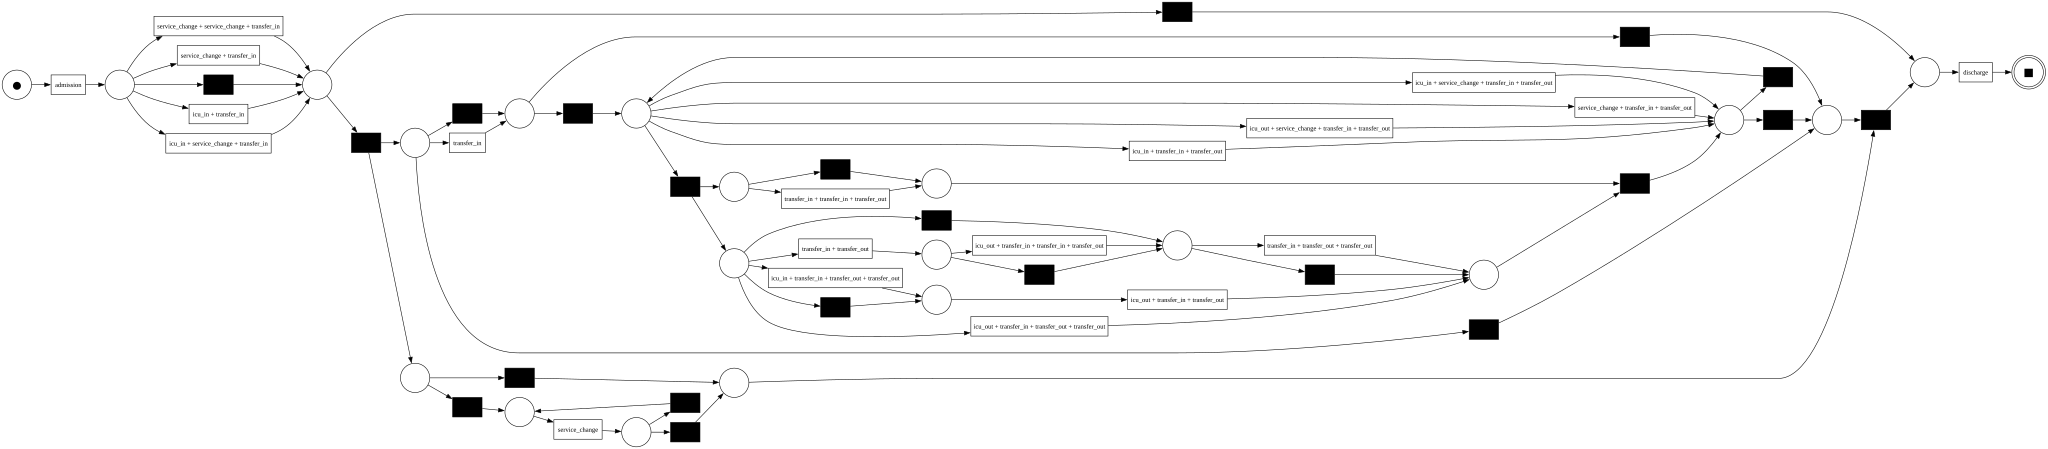

In [ ]:
import os
import shutil
from pathlib import Path

import pm4py
from IPython.display import SVG, display


network_folder = Path(r"D:\Универ\4 курс\Диплом")

graphviz_folder = Path(r"C:\Program Files\Graphviz\bin")

if shutil.which("dot") is None and (graphviz_folder / "dot.exe").is_file():
    os.environ["PATH"] = str(graphviz_folder) + os.pathsep + os.environ["PATH"]

if shutil.which("dot") is None:
    raise RuntimeError(
        "Python не нашёл dot.exe"
    )


network_files = [
    ("События отдельно", "mimic3_train_separate.pnml"),
    ("Одновременные события вместе", "mimic3_train_grouped.pnml")
]

for network_title, network_filename in network_files:
    network_path = network_folder / network_filename
    image_path = network_path.with_suffix(".svg")

    petri_net, initial_marking, final_marking = pm4py.read_pnml(
        str(network_path)
    )

    pm4py.save_vis_petri_net(
        petri_net,
        initial_marking,
        final_marking,
        str(image_path)
    )

    print(network_title)
    print("Рисунок сохранён:", image_path)
    display(SVG(filename=str(image_path)))